In [ ]:
# CELL 1 — Upload and Load Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import glob
import os
import warnings
warnings.filterwarnings("ignore")

from google.colab import files

print("Please select Airline_Delay_Cause.csv.zip")

# Open upload window
uploaded = files.upload()

# Find the uploaded ZIP file
zip_files = glob.glob("/content/*.zip")

if not zip_files:
    print("\n❌ No ZIP file was uploaded.")
    print("Please run this cell again and select Airline_Delay_Cause.csv.zip")
else:
    zip_file = zip_files[0]

    # Extract ZIP
    with zipfile.ZipFile(zip_file, "r") as zip_ref:
        zip_ref.extractall("/content/airline_data")

    # Find CSV
    csv_files = glob.glob("/content/airline_data/*.csv")

    if not csv_files:
        print("❌ No CSV file was found inside the ZIP file.")
    else:
        csv_file = csv_files[0]

        # Load dataset
        df = pd.read_csv(csv_file)

        print("\n✅ Dataset loaded successfully!")
        print("Rows:", df.shape[0])
        print("Columns:", df.shape[1])

        display(df.head())

Please select Airline_Delay_Cause.csv.zip


Saving Airline_Delay_Cause.csv.zip to Airline_Delay_Cause.csv.zip

✅ Dataset loaded successfully!
Rows: 171666
Columns: 21


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2023,8,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",89.0,13.0,2.25,1.60,3.16,0.0,5.99,2.0,1.0,1375.0,71.0,761.0,118.0,0.0,425.0
1,2023,8,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",62.0,10.0,1.97,0.04,0.57,0.0,7.42,0.0,1.0,799.0,218.0,1.0,62.0,0.0,518.0
2,2023,8,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",62.0,10.0,2.73,1.18,1.80,0.0,4.28,1.0,0.0,766.0,56.0,188.0,78.0,0.0,444.0
3,2023,8,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",66.0,12.0,3.69,2.27,4.47,0.0,1.57,1.0,1.0,1397.0,471.0,320.0,388.0,0.0,218.0
4,2023,8,9E,Endeavor Air Inc.,ALB,"Albany, NY: Albany International",92.0,22.0,7.76,0.00,2.96,0.0,11.28,2.0,0.0,1530.0,628.0,0.0,134.0,0.0,768.0


In [ ]:
# ============================================================
# DATA CLEANING AND FEATURE ENGINEERING
# ============================================================

data = df.copy()

# Remove duplicate records
data = data.drop_duplicates()

# Convert numeric columns
numeric_columns = [
    "year", "month", "arr_flights", "arr_del15",
    "arr_cancelled", "arr_diverted", "arr_delay",
    "carrier_delay", "weather_delay",
    "nas_delay", "security_delay",
    "late_aircraft_delay"
]

for col in numeric_columns:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Calculate delay rate
data["delay_rate"] = (
    data["arr_del15"] / data["arr_flights"]
) * 100

# Average delay per delayed flight
data["avg_delay"] = (
    data["arr_delay"] / data["arr_del15"]
)

# Replace invalid infinite values
data = data.replace([np.inf, -np.inf], np.nan)

# Month names
month_names = {
    1:"January", 2:"February", 3:"March",
    4:"April", 5:"May", 6:"June",
    7:"July", 8:"August", 9:"September",
    10:"October", 11:"November", 12:"December"
}

data["month_name"] = data["month"].map(month_names)

print("Cleaning completed!")
print("Remaining records:", len(data))

display(data.head())

Cleaning completed!
Remaining records: 171666


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,delay_rate,avg_delay,month_name
0,2023,8,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",89.0,13.0,2.25,1.60,3.16,0.0,5.99,2.0,1.0,1375.0,71.0,761.0,118.0,0.0,425.0,14.606742,105.769231,August
1,2023,8,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",62.0,10.0,1.97,0.04,0.57,0.0,7.42,0.0,1.0,799.0,218.0,1.0,62.0,0.0,518.0,16.129032,79.900000,August
2,2023,8,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",62.0,10.0,2.73,1.18,1.80,0.0,4.28,1.0,0.0,766.0,56.0,188.0,78.0,0.0,444.0,16.129032,76.600000,August
3,2023,8,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",66.0,12.0,3.69,2.27,4.47,0.0,1.57,1.0,1.0,1397.0,471.0,320.0,388.0,0.0,218.0,18.181818,116.416667,August
4,2023,8,9E,Endeavor Air Inc.,ALB,"Albany, NY: Albany International",92.0,22.0,7.76,0.00,2.96,0.0,11.28,2.0,0.0,1530.0,628.0,0.0,134.0,0.0,768.0,23.913043,69.545455,August


In [ ]:
# ============================================================
# OVERALL AIRLINE DELAY ANALYSIS
# ============================================================

total_flights = data["arr_flights"].sum()
total_delayed = data["arr_del15"].sum()
total_delay = data["arr_delay"].sum()

overall_delay_rate = (
    total_delayed / total_flights
) * 100

print("=" * 55)
print("AIRLINE DELAY ANALYSIS")
print("=" * 55)

print(f"Total arriving flights      : {total_flights:,.0f}")
print(f"Flights delayed 15+ minutes : {total_delayed:,.0f}")
print(f"Total delay minutes         : {total_delay:,.0f}")
print(f"Overall delay rate          : {overall_delay_rate:.2f}%")

print("\nMissing values:")
print(data.isnull().sum().sum())

print("\nNumber of duplicate records:")
print(data.duplicated().sum())

AIRLINE DELAY ANALYSIS
Total arriving flights      : 62,146,805
Flights delayed 15+ minutes : 11,375,095
Total delay minutes         : 726,758,355
Overall delay rate          : 18.30%

Missing values:
11274

Number of duplicate records:
0


DELAY ROOT-CAUSE SUMMARY


,Cause,Delay Minutes,Percentage
4,Late Aircraft / Rotation,283144335.0,38.959940
0,Carrier / Operational,246370897.0,33.900008
2,Air Traffic / NAS,157823639.0,21.716131
1,Weather,38153170.0,5.249779
3,Security,1265591.0,0.174142


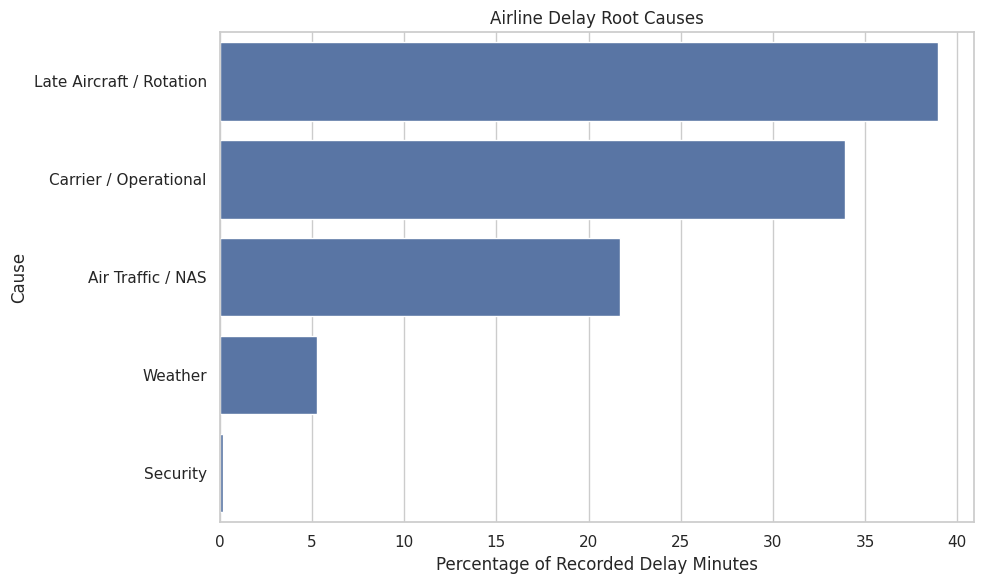

In [ ]:
# ============================================================
# ROOT-CAUSE ANALYSIS
# ============================================================

causes = {
    "Carrier / Operational": "carrier_delay",
    "Weather": "weather_delay",
    "Air Traffic / NAS": "nas_delay",
    "Security": "security_delay",
    "Late Aircraft / Rotation": "late_aircraft_delay"
}

# Calculate total delay minutes for each cause
cause_data = []

for cause, column in causes.items():
    total = data[column].sum()
    cause_data.append([cause, total])

cause_summary = pd.DataFrame(
    cause_data,
    columns=["Cause", "Delay Minutes"]
)

# Calculate percentage
cause_summary["Percentage"] = (
    cause_summary["Delay Minutes"]
    / cause_summary["Delay Minutes"].sum()
) * 100

cause_summary = cause_summary.sort_values(
    "Delay Minutes",
    ascending=False
)

print("DELAY ROOT-CAUSE SUMMARY")
display(cause_summary)

# Find dominant root cause for every record
cause_columns = list(causes.values())

data["dominant_root_cause"] = (
    data[cause_columns]
    .idxmax(axis=1)
    .map({v:k for k,v in causes.items()})
)

# Visualization
plt.figure(figsize=(10,6))

sns.barplot(
    data=cause_summary,
    x="Percentage",
    y="Cause"
)

plt.title("Airline Delay Root Causes")
plt.xlabel("Percentage of Recorded Delay Minutes")
plt.ylabel("Cause")

plt.tight_layout()
plt.show()

MONTHLY DELAY RATE


,month,flights,delayed,delay_rate,month_name
0,1,5037397.0,918519.0,18.234001,January
1,2,4653341.0,855134.0,18.376775,February
2,3,5457777.0,928208.0,17.007071,March
3,4,4988672.0,848691.0,17.012363,April
4,5,5050013.0,907663.0,17.973478,May
5,6,5175726.0,1173371.0,22.670655,June
6,7,5490440.0,1204979.0,21.946857,July
7,8,6034001.0,1209494.0,20.044644,August
8,9,4969482.0,703938.0,14.165219,September
9,10,5206266.0,792054.0,15.213475,October



YEARLY DELAY RATE


,year,flights,delayed,delay_rate
0,2013,2629106.0,493432.0,18.768053
1,2014,5819811.0,1240528.0,21.315606
2,2015,5819079.0,1063439.0,18.275040
3,2016,5617658.0,964239.0,17.164430
4,2017,5674621.0,1029474.0,18.141723
5,2018,7206195.0,1352165.0,18.763925
6,2019,7422037.0,1389253.0,18.717948
7,2020,4688354.0,431921.0,9.212636
8,2021,5995397.0,1010332.0,16.851795
9,2022,6729125.0,1376798.0,20.460283



SEASONAL DELAY RATE


,season,flights,delayed,delay_rate
0,Autumn,15161190.0,2247532.0,14.824245
1,Spring,15496462.0,2684562.0,17.323709
2,Summer,16700167.0,3587844.0,21.483881
3,Winter,14788986.0,2855157.0,19.305969


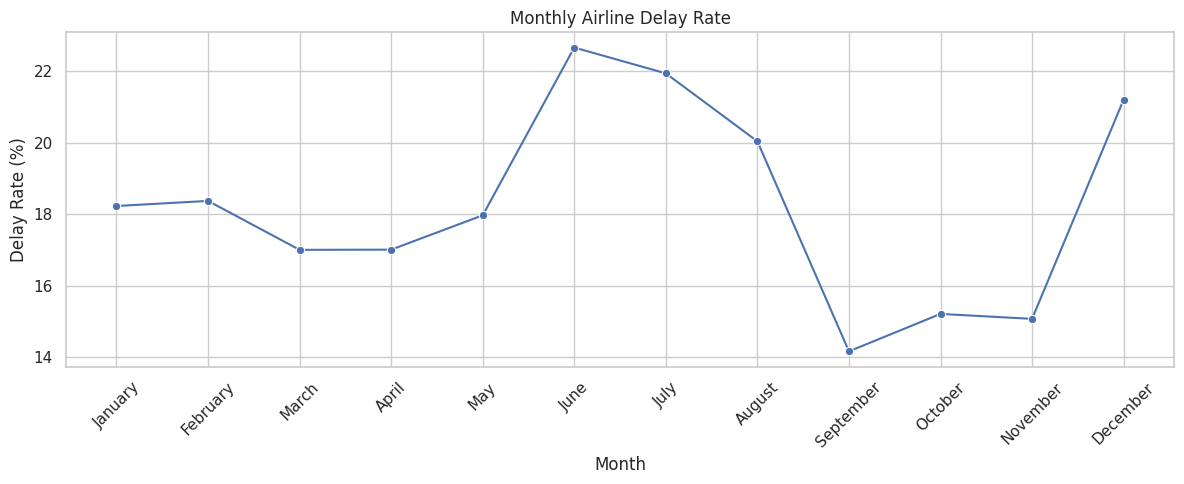

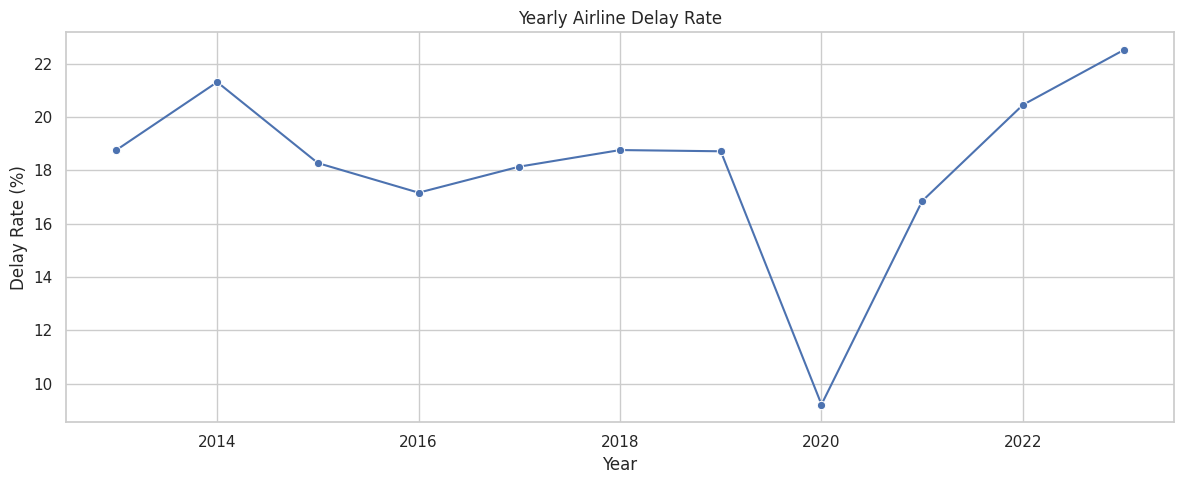

In [ ]:
# ============================================================
# TIME-BASED ANALYSIS
# ============================================================

# ---------- MONTHLY ANALYSIS ----------

monthly = data.groupby("month").agg(
    flights=("arr_flights", "sum"),
    delayed=("arr_del15", "sum")
).reset_index()

monthly["delay_rate"] = (
    monthly["delayed"] / monthly["flights"]
) * 100

monthly["month_name"] = monthly["month"].map(month_names)

# ---------- YEARLY ANALYSIS ----------

yearly = data.groupby("year").agg(
    flights=("arr_flights", "sum"),
    delayed=("arr_del15", "sum")
).reset_index()

yearly["delay_rate"] = (
    yearly["delayed"] / yearly["flights"]
) * 100

# ---------- SEASONAL ANALYSIS ----------

def season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

data["season"] = data["month"].apply(season)

seasonal = data.groupby("season").agg(
    flights=("arr_flights", "sum"),
    delayed=("arr_del15", "sum")
).reset_index()

seasonal["delay_rate"] = (
    seasonal["delayed"] / seasonal["flights"]
) * 100


# ---------- DISPLAY RESULTS ----------

print("MONTHLY DELAY RATE")
display(monthly)

print("\nYEARLY DELAY RATE")
display(yearly)

print("\nSEASONAL DELAY RATE")
display(seasonal)


# ---------- MONTHLY GRAPH ----------

plt.figure(figsize=(12,5))

sns.lineplot(
    data=monthly,
    x="month_name",
    y="delay_rate",
    marker="o"
)

plt.title("Monthly Airline Delay Rate")
plt.xlabel("Month")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ---------- YEARLY GRAPH ----------

plt.figure(figsize=(12,5))

sns.lineplot(
    data=yearly,
    x="year",
    y="delay_rate",
    marker="o"
)

plt.title("Yearly Airline Delay Rate")
plt.xlabel("Year")
plt.ylabel("Delay Rate (%)")

plt.grid(True)
plt.tight_layout()
plt.show()

AIRLINE DELAY ANALYSIS


,carrier,flights,delayed,delay_minutes,delay_rate
6,F9,1158943.0,291403.0,20351939.0,25.143860
3,B6,2609697.0,647919.0,46001696.0,24.827365
8,G4,613357.0,149943.0,10837875.0,24.446285
11,NK,1526076.0,330708.0,22589292.0,21.670480
17,VX,301908.0,64605.0,3805664.0,21.398903
5,EV,2786903.0,570250.0,39988678.0,20.461781
18,WN,12522217.0,2460563.0,124294977.0,19.649580
10,MQ,2352968.0,455757.0,27432851.0,19.369452
1,AA,7973061.0,1538261.0,103761183.0,19.293230
15,UA,5464237.0,1030741.0,70288103.0,18.863402



TOP AIRPORTS BY DELAY RATE


,airport,flights,delayed,delay_minutes,delay_rate
52,BQN,17708.0,5585.0,363530.0,31.539417
284,PGD,32933.0,9489.0,716369.0,28.813045
336,SFB,54489.0,14796.0,1157509.0,27.154104
29,AZA,31844.0,8628.0,597334.0,27.094586
372,TTN,23356.0,6102.0,464415.0,26.126049
22,ASE,55076.0,13763.0,1082030.0,24.989106
128,EWR,1166485.0,288816.0,21360531.0,24.759513
291,PIE,43272.0,10452.0,805645.0,24.154187
346,SJU,267274.0,62672.0,3902923.0,23.448596
337,SFO,1501997.0,345825.0,23689885.0,23.024347


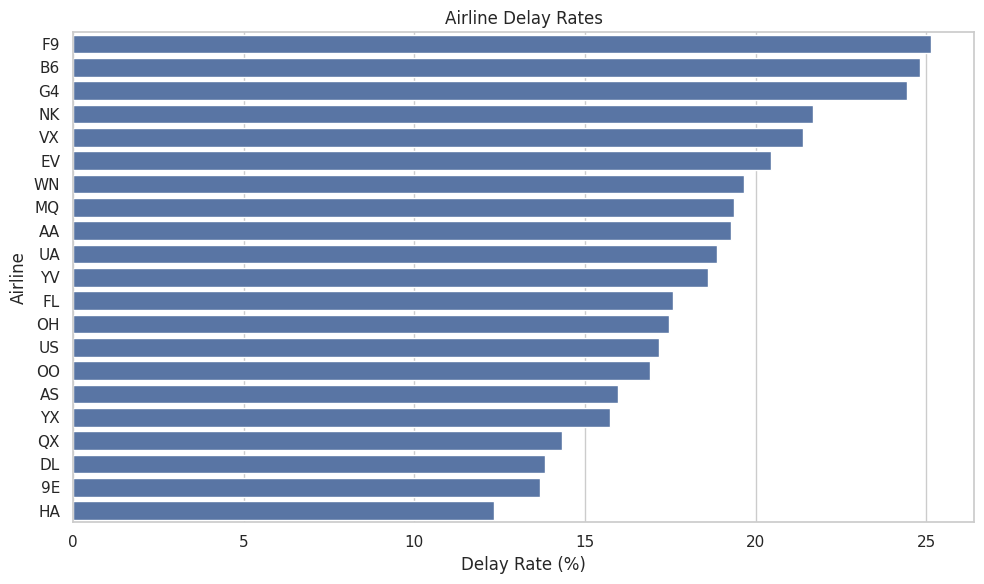

In [ ]:
# ============================================================
# AIRLINE AND AIRPORT ANALYSIS
# ============================================================

# ---------- AIRLINE ANALYSIS ----------

airlines = data.groupby("carrier").agg(
    flights=("arr_flights", "sum"),
    delayed=("arr_del15", "sum"),
    delay_minutes=("arr_delay", "sum")
).reset_index()

airlines["delay_rate"] = (
    airlines["delayed"] / airlines["flights"]
) * 100

airlines = airlines.sort_values(
    "delay_rate",
    ascending=False
)

print("AIRLINE DELAY ANALYSIS")
display(airlines)


# ---------- AIRPORT ANALYSIS ----------

airports = data.groupby("airport").agg(
    flights=("arr_flights", "sum"),
    delayed=("arr_del15", "sum"),
    delay_minutes=("arr_delay", "sum")
).reset_index()

airports["delay_rate"] = (
    airports["delayed"] / airports["flights"]
) * 100

# Only include airports with reasonable traffic volume
airports = airports[
    airports["flights"] >= 10000
]

airports = airports.sort_values(
    "delay_rate",
    ascending=False
)

print("\nTOP AIRPORTS BY DELAY RATE")
display(airports.head(15))


# ---------- AIRLINE GRAPH ----------

plt.figure(figsize=(10,6))

sns.barplot(
    data=airlines,
    x="delay_rate",
    y="carrier"
)

plt.title("Airline Delay Rates")
plt.xlabel("Delay Rate (%)")
plt.ylabel("Airline")

plt.tight_layout()
plt.show()

MACHINE LEARNING RESULTS
Model Accuracy: 69.17%

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.92      0.80     23074
           1       0.58      0.21      0.31     11212

    accuracy                           0.69     34286
   macro avg       0.64      0.57      0.56     34286
weighted avg       0.66      0.69      0.64     34286



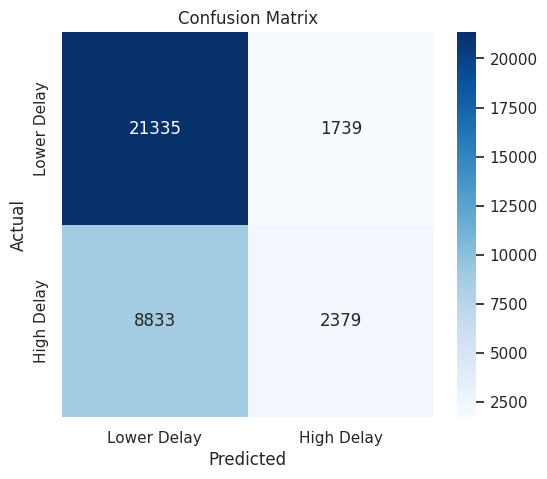

In [ ]:
# ============================================================
# MACHINE LEARNING - HIGH DELAY PREDICTION
# ============================================================

# Define high delay as 25% or more delayed flights
data["high_delay"] = (
    data["delay_rate"] >= 25
).astype(int)

# Select features
features = [
    "year",
    "month",
    "carrier",
    "airport",
    "arr_flights",
    "arr_cancelled",
    "arr_diverted"
]

target = "high_delay"

ml_data = data[
    features + [target]
].dropna()

# Sort chronologically
ml_data = ml_data.sort_values(
    ["year", "month"]
)

# 80/20 chronological split
split = int(len(ml_data) * 0.8)

train = ml_data.iloc[:split]
test = ml_data.iloc[split:]

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]


# Numerical and categorical columns
numeric_features = [
    "year",
    "month",
    "arr_flights",
    "arr_cancelled",
    "arr_diverted"
]

categorical_features = [
    "carrier",
    "airport"
]


# Preprocessing
preprocessor = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        numeric_features
    ),
    (
        "categorical",
        OneHotEncoder(
            handle_unknown="ignore"
        ),
        categorical_features
    )
])


# Logistic Regression
model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    )
])


# Train model
model.fit(
    X_train,
    y_train
)

# Predictions
predictions = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(
    y_test,
    predictions
)

print("=" * 55)
print("MACHINE LEARNING RESULTS")
print("=" * 55)

print(
    f"Model Accuracy: {accuracy * 100:.2f}%"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        predictions
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Lower Delay", "High Delay"],
    yticklabels=["Lower Delay", "High Delay"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
# ============================================================
# FINAL PROJECT SUMMARY
# ============================================================

main_cause = cause_summary.iloc[0]

highest_month = monthly.loc[
    monthly["delay_rate"].idxmax()
]

highest_airline = airlines.iloc[0]

print("=" * 70)
print("          AIRLINE DELAY ROOT-CAUSE ANALYZER")
print("                    FINAL SUMMARY")
print("=" * 70)

print(f"""
PROJECT OBJECTIVE
-----------------
The objective of this project was to analyze historical airline
records and identify the main recorded causes of flight delays.

DATASET
-------
Number of records : {len(data):,}
Years covered     : {data['year'].min():.0f} - {data['year'].max():.0f}

OVERALL RESULTS
---------------
Total flights             : {total_flights:,.0f}
Flights delayed 15+ mins  : {total_delayed:,.0f}
Overall delay rate        : {overall_delay_rate:.2f}%

MAIN RECORDED ROOT CAUSE
------------------------
{main_cause['Cause']}
Share of delay minutes    : {main_cause['Percentage']:.2f}%

HIGHEST-DELAY MONTH
-------------------
{highest_month['month_name']}
Delay rate                : {highest_month['delay_rate']:.2f}%

AIRLINE ANALYSIS
----------------
Airline with highest calculated delay rate:
{highest_airline['carrier']}
Delay rate                : {highest_airline['delay_rate']:.2f}%

MACHINE LEARNING
----------------
Model                  : Logistic Regression
Target                 : High Delay (>= 25%)
Accuracy               : {accuracy * 100:.2f}%

IMPORTANT LIMITATION
--------------------
The dataset does not contain a dedicated maintenance-delay field.
Therefore, this project does not directly measure maintenance
delays. Carrier delay is treated as an operational/airline-related
category, while Late Aircraft / Rotation is kept as a separate
category.

CONCLUSION
----------
The analysis shows that airline delays have multiple recorded
causes and that their contribution varies across time, airlines,
and airports. The analyzer can help identify recurring patterns
that may be useful for operational planning and further analysis.
""")

print("=" * 70)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 70)

          AIRLINE DELAY ROOT-CAUSE ANALYZER
                    FINAL SUMMARY

PROJECT OBJECTIVE
-----------------
The objective of this project was to analyze historical airline
records and identify the main recorded causes of flight delays.

DATASET
-------
Number of records : 171,666
Years covered     : 2013 - 2023

OVERALL RESULTS
---------------
Total flights             : 62,146,805
Flights delayed 15+ mins  : 11,375,095
Overall delay rate        : 18.30%

MAIN RECORDED ROOT CAUSE
------------------------
Late Aircraft / Rotation
Share of delay minutes    : 38.96%

HIGHEST-DELAY MONTH
-------------------
June
Delay rate                : 22.67%

AIRLINE ANALYSIS
----------------
Airline with highest calculated delay rate:
F9
Delay rate                : 25.14%

MACHINE LEARNING
----------------
Model                  : Logistic Regression
Target                 : High Delay (>= 25%)
Accuracy               : 69.17%

IMPORTANT LIMITATION
--------------------
The dataset does not cont